In [8]:
from google.colab import drive, userdata
import os, shutil

drive.mount('/content/drive')

project_dir = "/content/drive/MyDrive/project3"
os.makedirs(project_dir, exist_ok=True)

# copy the script and any existing data into Drive
shutil.copy("/content/fetch_brand_youtube.py", project_dir)
if os.path.exists("/content/data"):
    shutil.copytree("/content/data", project_dir + "/data", dirs_exist_ok=True)

os.chdir(project_dir)
os.environ["YOUTUBE_API_KEY"] = userdata.get("YOUTUBE_API_KEY")

print("Working folder:", os.getcwd())
print("Files:", sorted(os.listdir(".")))
if os.path.exists("data/raw"):
    print("Existing data files:", sorted(os.listdir("data/raw")))

Mounted at /content/drive
Working folder: /content/drive/MyDrive/project3
Files: ['data', 'fetch_brand_youtube.py']
Existing data files: ['done_Limelight.txt', 'table_a_posts_Limelight.csv', 'table_b_comments_Limelight.csv']


In [9]:
!python fetch_brand_youtube.py --channel @Khaadi --brand Khaadi

Finding channel uploads...
Videos found: 827
Saved 827 posts -> data/raw/table_a_posts_Khaadi.csv
[14/827] bplJV_I0hRE: 2 comments (total this run: 2)
[39/827] mCDDlPA1Yxo: 1 comments (total this run: 3)
[46/827] WzA5MPKugHs: 1 comments (total this run: 4)
[47/827] uqSI3rO09K0: 1 comments (total this run: 5)
[49/827] zYCx1OIDzd4: 1 comments (total this run: 6)
[54/827] zD2qtqMKMBQ: 2 comments (total this run: 8)
[55/827] m9jAKFQsK4Q: 4 comments (total this run: 12)
[56/827] jK18ez6VYWc: 1 comments (total this run: 13)
[60/827] C983Un7FDrw: 1 comments (total this run: 14)
[62/827] 0uzuDFTHLkM: 1 comments (total this run: 15)
[76/827] YGwotXGvv_E: 3 comments (total this run: 18)
[77/827] 7oV1XZZKUI8: 2 comments (total this run: 20)
[83/827] I34PCQ5DuAo: 1 comments (total this run: 21)
[86/827] YnLWrdGPNUc: 1 comments (total this run: 22)
[88/827] XaF_HmDpGhc: 2 comments (total this run: 24)
[89/827] isxgbSZZaoA: 1 comments (total this run: 25)
[90/827] 6ZD7st_ZjVg: 4 comments (total this

In [10]:
!python fetch_brand_youtube.py --channel @SapphirePakistan --brand Sapphire

Finding channel uploads...
Videos found: 2534
Saved 2534 posts -> data/raw/table_a_posts_Sapphire.csv
[3/2534] 5aoTLXdy1Lo: 1 comments (total this run: 1)
[11/2534] m2MhboWs5ZA: 1 comments (total this run: 2)
[13/2534] tCdn4hv5ETk: 1 comments (total this run: 3)
[16/2534] QrdJtA0TDwY: 1 comments (total this run: 4)
[19/2534] xqob3o_RAq4: 1 comments (total this run: 5)
[22/2534] nRJYsduNmNk: 1 comments (total this run: 6)
[26/2534] I2vKBcCMlHE: 1 comments (total this run: 7)
[31/2534] SZ0JDqIxu6c: 2 comments (total this run: 9)
[33/2534] tJA10wQzhkg: 1 comments (total this run: 10)
[41/2534] JCR_e6E8M7A: 1 comments (total this run: 11)
[42/2534] 4enx4Z3YvRY: 5 comments (total this run: 16)
[45/2534] Y5_dZ6CCQLE: 1 comments (total this run: 17)
[48/2534] tj1fuFRXz8A: 1 comments (total this run: 18)
[51/2534] OcFxgLd09i0: 1 comments (total this run: 19)
[57/2534] SawXUDzL3W0: 2 comments (total this run: 21)
[63/2534] AV80jBMjwqE: 1 comments (total this run: 22)
[67/2534] DYE7v3uXoas: 1 co

In [11]:
import glob
import pandas as pd

raw = "data/raw"
posts = pd.concat(
    [pd.read_csv(f) for f in sorted(glob.glob(f"{raw}/table_a_posts_*.csv"))],
    ignore_index=True,
)
comments = pd.concat(
    [pd.read_csv(f) for f in sorted(glob.glob(f"{raw}/table_b_comments_*.csv"))],
    ignore_index=True,
)
comments = comments.merge(
    posts.drop_duplicates("post_id")[["post_id", "brand"]], on="post_id", how="left"
)

print("Posts:", len(posts))
print(posts["brand"].value_counts(), "\n")
print("Comments:", len(comments))
print(comments["brand"].value_counts(), "\n")
print("Duplicate comment ids:", comments["comment_id"].duplicated().sum())
print("Empty comments:", comments["comment_text"].isna().sum(), "\n")
print(comments["language_type"].value_counts(), "\n")

top = comments.groupby("post_id").size().sort_values(ascending=False).head(10)
info = posts.drop_duplicates("post_id").set_index("post_id").loc[top.index, ["brand", "title"]]
info["comments"] = top.values
print("Videos with the most comments:")
print(info.to_string(), "\n")

print("Most repeated comments:")
print(comments["comment_text"].str.lower().str.strip().value_counts().head(15))

Posts: 3831
brand
Sapphire     2534
Khaadi        827
Limelight     470
Name: count, dtype: int64 

Comments: 7016
brand
Khaadi       3587
Sapphire     3072
Limelight     357
Name: count, dtype: int64 

Duplicate comment ids: 0
Empty comments: 0 

language_type
English       6509
Roman Urdu     391
Urdu           116
Name: count, dtype: int64 

Videos with the most comments:
                brand                                                                                         title  comments
post_id                                                                                                                      
28lYJjJ4Cp4    Khaadi                                                                   Khaadi X Esra | My Symphony       832
UZXcyktS180    Khaadi                                                                           KHAADI X ESRA | BTS       819
y_h54J1udLc  Sapphire     Get to Know Shadab Khan & Naseem Shah with SAPPHIRE | Menswear Collection | Available Now   

In [12]:
import os
import re
import glob
import pandas as pd

raw = "data/raw"
os.makedirs("data/clean", exist_ok=True)

posts = pd.concat(
    [pd.read_csv(f) for f in sorted(glob.glob(f"{raw}/table_a_posts_*.csv"))],
    ignore_index=True,
).drop_duplicates("post_id")
comments = pd.concat(
    [pd.read_csv(f) for f in sorted(glob.glob(f"{raw}/table_b_comments_*.csv"))],
    ignore_index=True,
).drop_duplicates("comment_id")
comments = comments.merge(posts[["post_id", "brand"]], on="post_id", how="left")

url_pattern = re.compile(r"(https?://|www\.|youtu\.be|\.com/)", re.I)
generic_words = {
    "nice", "wow", "hi", "hello", "yes", "ok", "okay", "good", "great",
    "beautiful", "lovely", "love", "amazing", "superb", "gorgeous", "awesome",
    "cute", "pretty", "perfect", "best", "like", "super", "excellent",
}

text = comments["comment_text"].astype(str).str.strip()
letters_only = text.str.replace(r"[^\w\s]|_", "", regex=True).str.strip()

comments["text_clean"] = text.str.lower().str.replace(r"\s+", " ", regex=True)
comments["is_spam_link"] = text.apply(lambda t: bool(url_pattern.search(t)))
comments["is_emoji_only"] = letters_only.eq("")
comments["word_count"] = letters_only.str.split().str.len()
comments["is_generic_praise"] = letters_only.str.lower().isin(generic_words)

clean = comments[~comments["is_spam_link"] & ~comments["is_emoji_only"]].copy()

posts.to_csv("data/clean/posts_all.csv", index=False, encoding="utf-8-sig")
comments.to_csv("data/clean/comments_all_flagged.csv", index=False, encoding="utf-8-sig")
clean.to_csv("data/clean/comments_clean.csv", index=False, encoding="utf-8-sig")

print("All comments:", len(comments))
print("Spam links removed:", int(comments["is_spam_link"].sum()))
print("Emoji-only removed:", int(comments["is_emoji_only"].sum()))
print("Clean comments kept:", len(clean))
print("Generic praise (kept, flagged):", int(clean["is_generic_praise"].sum()))
print(clean["brand"].value_counts())

All comments: 7016
Spam links removed: 328
Emoji-only removed: 387
Clean comments kept: 6301
Generic praise (kept, flagged): 309
brand
Khaadi       3196
Sapphire     2814
Limelight     291
Name: count, dtype: int64


In [13]:
import pandas as pd

clean = pd.read_csv("data/clean/comments_clean.csv")
t = clean["text_clean"].fillna("")

# order matters: the first matching topic becomes the primary topic
topic_rules = {
    "delivery": r"deliver|shipping|shipment|courier|tracking|dispatch|parcel|not received|still waiting|kitne din|received|ordered",
    "customer_service": r"refund|return|exchange|complain|customer service|customer care|no response|no reply|not responding|scam|fraud|cheat|disappointed|poor service",
    "discount": r"discount|\bsale\b|\boffers?\b|voucher|coupon|promo|\d+\s?%|percent|\bflat\b|clearance",
    "availability": r"available|availability|in stock|out of stock|\bstock\b|outlet|branch|where can|which city|kahan|kahaan|international|\bkarachi\b|\blahore\b|\bislamabad\b|\bpeshawar\b|\bquetta\b|\bmultan\b|\bfaisalabad\b|\bdubai\b|\busa\b|\buk\b|\bcanada\b",
    "size": r"\bsizes?\b|\bxs\b|\bxl\b|\bxxl\b|plus size|fitting|\blength\b|\bsmall\b|\bmedium\b|\blarge\b|\bfit\b|\bfits\b",
    "fabric_quality": r"fabric|quality|material|stitch|cotton|\bcloth|kapra|kapray|kapre|fading|faded|shrink|texture|silk|chiffon|linen|khaddar",
    "price": r"\bprices?\b|\bpricing\b|\bcost\b|\brates?\b|how much|kitn[ae]\b|kitni\b|qeemat|keemat|kimat|\bpkr\b|\brs\.?\s?\d|expensive|mehng|mahng|\bsast[aie]\b|\bcheap\b|\bbudget\b",
    "buying_intent": r"inbox|\bdm\b|whatsapp|contact|\bnumber\b|how to (order|buy)|want to (buy|order)|\bbuy\b|purchase|interested|chahiye|chahye|chahiyay|send (me )?(the )?details|\bdetails\b",
    "music_celebrity": r"\bsongs?\b|\bmusic\b|lyrics|singer|soundtrack|\bost\b",
    "praise": r"beautiful|gorgeous|stunning|lovely|\bnice\b|\bwow\b|amazing|awesome|\blove\b|pretty|elegant|mashallah|masha allah|khoobsurat|khubsurat|pyari|zabardast|\bsuper\b|\bperfect\b|\bbest\b|\bgood\b|\bgreat\b|\bcute\b|superb|excellent|fantastic",
}

for name, pattern in topic_rules.items():
    clean[f"has_{name}"] = t.str.contains(pattern, case=False, regex=True)

def primary_topic(row):
    for name in topic_rules:
        if row[f"has_{name}"]:
            return name
    return "other"

clean["topic"] = clean.apply(primary_topic, axis=1)

strong_intent = r"inbox|\bdm\b|whatsapp|contact|\bnumber\b|how to (order|buy)|want to (buy|order)|\bbuy\b|purchase|interested|chahiye|chahye|chahiyay|send (me )?(the )?details"
inquiry_cols = ["has_price", "has_discount", "has_availability", "has_size"]

clean["purchase_intent"] = "None"
clean.loc[clean[inquiry_cols].any(axis=1), "purchase_intent"] = "Possible inquiry"
clean.loc[t.str.contains(strong_intent, case=False, regex=True), "purchase_intent"] = "Strong intent"

clean.to_csv("data/clean/comments_labeled.csv", index=False, encoding="utf-8-sig")

print("Topic counts:")
print(clean["topic"].value_counts(), "\n")
print("Purchase intent counts:")
print(clean["purchase_intent"].value_counts(), "\n")

for name in list(topic_rules) + ["other"]:
    print(f"--- {name} (3 examples) ---")
    for c in clean.loc[clean["topic"] == name, "comment_text"].head(3):
        print("  ", str(c)[:100])

print("\n--- 20 random comments labeled other ---")
for c in clean.loc[clean["topic"] == "other", "comment_text"].sample(20, random_state=1):
    print("  ", str(c)[:100])

/tmp/ipykernel_579/3569807184.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean[f"has_{name}"] = t.str.contains(pattern, case=False, regex=True)
/tmp/ipykernel_579/3569807184.py:36: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean.loc[t.str.contains(strong_intent, case=False, regex=True), "purchase_intent"] = "Strong intent"


Topic counts:
topic
other               3431
praise              1580
music_celebrity      662
price                156
fabric_quality       133
discount              84
buying_intent         83
availability          81
customer_service      53
delivery              30
size                   8
Name: count, dtype: int64 

Purchase intent counts:
purchase_intent
None                5847
Possible inquiry     336
Strong intent        118
Name: count, dtype: int64 

--- delivery (3 examples) ---
   Just received wrong parcel instead of ordered suit
   Ye suit usa delivery hosakti ha USA page per to ye nahi ha
   Dc is 110 per order or per delivery as i added 3 dresses to cart so i saw that with each dress there
--- customer_service (3 examples) ---
   I had a bit of a problem with few returns with the customer service, however called customer service
   I had a bit of a problem with few returns with the customer service, however called customer service
   Khaadi, King Mall Gujranwala is not

In [14]:
import warnings
import pandas as pd

warnings.filterwarnings("ignore", message="This pattern is interpreted")

clean = pd.read_csv("data/clean/comments_clean.csv")

# 1) remove replies written by the brand's own support team
brand_reply_pattern = (
    r"thank you for (?:contacting|reaching|your (?:feedback|patience|concern))"
    r"|for further assistance|dear (?:customer|valued)|you can (?:find|reach|contact) us"
    r"|our (?:customer )?(?:team|support)|we apologi[sz]e"
)
is_reply = clean["parent_id"].notna()
brand_reply = is_reply & clean["text_clean"].fillna("").str.contains(
    brand_reply_pattern, case=False, regex=True
)
print("Brand replies removed:", int(brand_reply.sum()))
clean = clean[~brand_reply].copy()

# 2) remove exact repeats by the same author on the same post
repeats = clean.duplicated(subset=["post_id", "author_hash", "text_clean"])
print("Repeated comments removed:", int(repeats.sum()))
clean = clean[~repeats].reset_index(drop=True)

t = clean["text_clean"].fillna("")

# 3) topic rules (the first matching topic becomes the primary topic)
topic_rules = {
    "delivery": r"deliver|shipping|shipment|courier|tracking|dispatch|parcel|not received|still waiting|kitne din|rec(?:ei|ie|eo)ve|ordered|wrong (?:item|suit|size|parcel)|defect|missing",
    "customer_service": r"refund|return|exchange|complain|customer service|customer care|no response|no reply|not responding|scam|fraud|cheat|poor service|shame on",
    "discount": r"discount|\bsale\b|\boffers?\b|voucher|coupon|promo|\d+\s?%|percent|\bflat\b|clearance",
    "availability": r"available|availability|in stock|out of stock|\bstock\b|outlet|branch|where can|which city|kahan|kahaan|international|\bkarachi\b|\blahore\b|\bislamabad\b|\bpeshawar\b|\bquetta\b|\bmultan\b|\bfaisalabad\b|\bdubai\b|\busa\b|\buk\b|\bcanada\b|kab aa|kb aa",
    "size": r"\bsizes?\b|\bxs\b|plus size|fitting|\bfit\b|\bfits\b|\bsmall\b|\bmedium\b|\blarge\b",
    "fabric_quality": r"fabric|quality|material|stitch|cotton|kapra|kapray|kapre|fading|faded|shrink|texture|silk|chiffon|linen|khaddar|colou?r",
    "price": r"\bprices?\b|\bpricing\b|\bcost\b|\brates?\b|how much|kitn[ae]\b|kitni\b|qeemat|keemat|kimat|\bpkr\b|\brs\.?\s?\d|expensive|mehng|mahng|\bsast[aie]\b|\bcheap\b|\bbudget\b",
    "buying_intent": r"inbox|\bdm\b|whatsapp|contact|\bnumber\b|how to (?:order|buy)|want to (?:buy|order)|\bbuy\b|purchase|interested|chahiye|chahye|chahiyay|send (?:me )?(?:the )?details|\bdetails\b",
    "negative_feedback": r"\bbad\b|worst|bakwas|bekar|sucks|\bfake\b|waste|horrible|terrible|pathetic|disappoint|overrated|boring|ugly|useless|not good|nahi acha|acha nahi",
    "celebrity_music": r"\bsongs?\b|\bmusic\b|lyrics|singer|soundtrack|\bost\b|esra|shadab|naseem|yumna|\bahad\b|hasan|raheem|risham|\bdance\b|\bvoice\b",
    "praise": r"beautiful|gorgeous|stunning|lovely|\bnice\b|\bwow\b|amazing|awesome|\blove\b|pretty|elegant|mashallah|masha allah|khoobsurat|khubsurat|pyari|zabardast|\bsuper\b|\bperfect\b|\bbest\b|\bgood\b|\bgreat\b|\bcute\b|cutie|superb|excellent|fantastic|beauty|\bqueen\b|\bacha\b|\bachi\b|\bachay\b|kamal|shandar|shaandar|behtareen|lajawab|\bmast\b|زبردست|خوبصورت|ماشاء|شاندار|پیاری|بہت",
}

for name, pattern in topic_rules.items():
    clean[f"has_{name}"] = t.str.contains(pattern, case=False, regex=True)

def primary_topic(row):
    for name in topic_rules:
        if row[f"has_{name}"]:
            return name
    return "other"

clean["topic"] = clean.apply(primary_topic, axis=1)

# very short leftovers are reactions, not real content
short_mask = (clean["topic"] == "other") & (clean["word_count"] <= 2)
clean.loc[short_mask, "topic"] = "short_reaction"

# 4) purchase intent
strong_intent = r"inbox|\bdm\b|whatsapp|contact|\bnumber\b|how to (?:order|buy)|want to (?:buy|order)|\bbuy\b|purchase|interested|chahiye|chahye|chahiyay|send (?:me )?(?:the )?details"
inquiry_cols = ["has_price", "has_discount", "has_availability", "has_size"]

clean["purchase_intent"] = "None"
clean.loc[clean[inquiry_cols].any(axis=1), "purchase_intent"] = "Possible inquiry"
clean.loc[t.str.contains(strong_intent, case=False, regex=True), "purchase_intent"] = "Strong intent"

clean.to_csv("data/clean/comments_labeled.csv", index=False, encoding="utf-8-sig")

print("\nComments now:", len(clean))
print(clean["topic"].value_counts(), "\n")
print(clean["purchase_intent"].value_counts(), "\n")

print("--- 25 random longer comments still labeled other ---")
pool = clean[(clean["topic"] == "other") & (clean["word_count"] >= 4)]
for c in pool["comment_text"].sample(min(25, len(pool)), random_state=2):
    print("  ", str(c)[:110])

Brand replies removed: 5
Repeated comments removed: 68

Comments now: 6228
topic
other                1796
celebrity_music      1469
praise               1265
short_reaction       1018
price                 153
fabric_quality        118
buying_intent          85
discount               84
availability           81
negative_feedback      65
customer_service       50
delivery               38
size                    6
Name: count, dtype: int64 

purchase_intent
None                5780
Possible inquiry     332
Strong intent        116
Name: count, dtype: int64 

--- 25 random longer comments still labeled other ---
   rishtaaaa neemoo koo rishtyyy kii bhottt jaldii haiii 😂😂
   @syedjoanmurtazax6357 oh you deleted your comment 😂😂 little mouse😂
   Hassan ans Roshaan at it again! ❤️
   By the way lawn ki collection daikh k lg raha k garmi aa nahi rhi garmi aa gae hai 😂😂😂
   LOL. No they didn't do it on purpose. But I clicked just to read the comments of other armys😂💜
   if you give them Hija

In [15]:
!pip install -q sentence-transformers

import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

comments = pd.read_csv("data/clean/comments_labeled.csv")
texts = comments["comment_text"].astype(str).str.slice(0, 300).tolist()

model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
embeddings = model.encode(
    texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True
)

np.save("data/clean/comment_embeddings.npy", embeddings)
print("Embeddings shape:", embeddings.shape)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/98 [00:00<?, ?it/s]

Embeddings shape: (6228, 384)


Rows in Spark: 6228
k=4  silhouette=0.1026
k=5  silhouette=0.1223
k=6  silhouette=0.1090
k=7  silhouette=0.1009
k=8  silhouette=0.1013
k=9  silhouette=0.0898
k=10  silhouette=0.1019
k=11  silhouette=0.1000
k=12  silhouette=0.0910


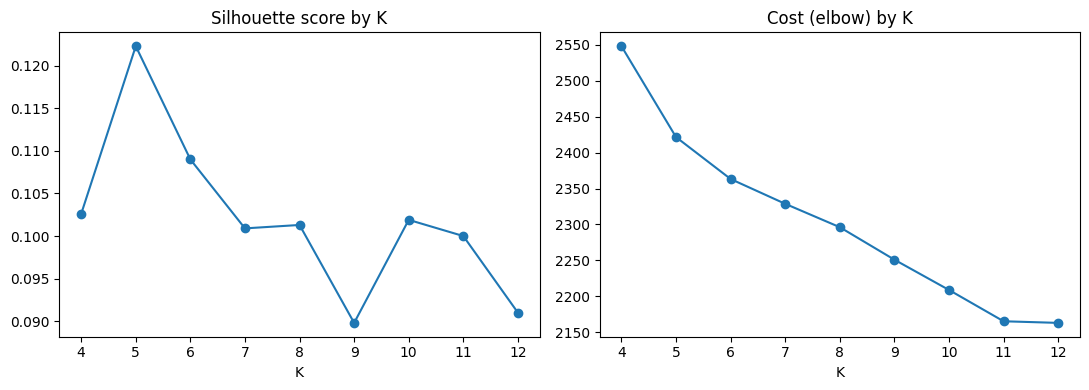

In [16]:
!pip install -q pyspark

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.ml.linalg import Vectors
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

spark = (
    SparkSession.builder.master("local[*]")
    .appName("campaign_intelligence")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

emb = np.load("data/clean/comment_embeddings.npy")
rows = [(int(i), Vectors.dense(v.tolist())) for i, v in enumerate(emb)]
df = spark.createDataFrame(rows, ["row_id", "features"]).cache()
print("Rows in Spark:", df.count())

evaluator = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="prediction",
    metricName="silhouette",
    distanceMeasure="cosine",
)

results = []
for k in range(4, 13):
    model = KMeans(
        k=k, seed=42, maxIter=50,
        featuresCol="features", predictionCol="prediction",
        distanceMeasure="cosine",
    ).fit(df)
    pred = model.transform(df)
    score = evaluator.evaluate(pred)
    results.append({"k": k, "silhouette": round(score, 4), "cost": round(model.summary.trainingCost, 2)})
    print(f"k={k}  silhouette={score:.4f}")

res = pd.DataFrame(results)
res.to_csv("data/clean/kmeans_k_selection.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(res["k"], res["silhouette"], marker="o")
ax[0].set_title("Silhouette score by K")
ax[0].set_xlabel("K")
ax[1].plot(res["k"], res["cost"], marker="o")
ax[1].set_title("Cost (elbow) by K")
ax[1].set_xlabel("K")
plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pandas as pd
from pyspark.ml.clustering import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

comments = pd.read_csv("data/clean/comments_labeled.csv")

tfidf = TfidfVectorizer(
    min_df=3, max_df=0.5, stop_words="english",
    token_pattern=r"(?u)\b[^\W\d_]{3,}\b",
)
X = tfidf.fit_transform(comments["text_clean"].fillna(""))
vocab = np.array(tfidf.get_feature_names_out())


def top_terms(mask, n=8):
    m = np.asarray(X[mask].mean(axis=0)).ravel()
    return ", ".join(vocab[m.argsort()[::-1][:n]])


for k in [5, 6, 8]:
    model = KMeans(
        k=k, seed=42, maxIter=50,
        featuresCol="features", predictionCol="prediction",
        distanceMeasure="cosine",
    ).fit(df)
    pred = (
        model.transform(df)
        .select("row_id", "prediction")
        .toPandas()
        .sort_values("row_id")
    )
    col = f"cluster_k{k}"
    comments[col] = pred["prediction"].values

    print(f"\n==================== K = {k} ====================")
    for c in range(k):
        mask = (comments[col] == c).values
        sub = comments[mask]
        shares = sub["topic"].value_counts(normalize=True).head(3)
        topics_str = ", ".join(f"{name} {share:.0%}" for name, share in shares.items())
        print(f"\n[Cluster {c}] size={int(mask.sum())} | topics: {topics_str}")
        print("  top words:", top_terms(mask))
        for s in sub["comment_text"].sample(min(4, len(sub)), random_state=3):
            print("   -", str(s)[:90])

comments.to_csv("data/clean/comments_clusters.csv", index=False, encoding="utf-8-sig")
print("\nSaved data/clean/comments_clusters.csv")


==================== K = 5 ====================

[Cluster 0] size=1834 | topics: short_reaction 39%, other 27%, praise 25%
  top words: nice, wow, good, amazing, esra, love, great, bts
   - Undedey
   - Stunning
   - @khayrulmasum7801 Why? it was a happy ending
   - Wow ooooooo eeee

[Cluster 1] size=2009 | topics: other 45%, celebrity_music 23%, short_reaction 12%
  top words: naseem, hai, pakistan, love, khaadi, shah, esra, yumna
   - Rahim Yar Khan City me ready to wear close krdea ha 😢😢
   - انڈین مویوی سے بای کاٹ پلیز میرے دوستون نے بھی کیا ہے ا پ بھی کر لے ایک  پاکستانی ہونے ک ن
   - dkdifkeoitrkofk8d       ijiumuktioit
   - Epic track....sonar karava marriage

[Cluster 2] size=611 | topics: other 23%, price 21%, praise 17%
  top words: price, collection, brand, sapphire, buy, good, sale, khaadi
   - Price
   - They just don't freaking know how to support their own content
   - Swsome collection
   - Excellent & very good quality ❤

[Cluster 3] size=718 | topics: celebrity_music

In [18]:
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml.linalg import Vectors
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from sklearn.feature_extraction.text import TfidfVectorizer

spark = (
    SparkSession.builder.master("local[*]")
    .appName("campaign_intelligence")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

comments = pd.read_csv("data/clean/comments_clusters.csv")
emb = np.load("data/clean/comment_embeddings.npy")

# 1) name the six first-level segments
segment_names = {
    0: "music_seekers",
    1: "celebrity_local_chat",
    2: "shoppers_price_askers",
    3: "looks_and_beauty",
    4: "generic_praise",
    5: "short_reactions_hype",
}
comments["segment"] = comments["cluster_k6"].map(segment_names)

print("Segments by brand (counts):")
print(pd.crosstab(comments["segment"], comments["brand"]), "\n")
print("Segments by brand (share of each brand, %):")
print((pd.crosstab(comments["segment"], comments["brand"], normalize="columns") * 100).round(1), "\n")

# 2) commercial subset
commercial_cols = [
    "has_price", "has_discount", "has_availability", "has_delivery",
    "has_size", "has_fabric_quality", "has_buying_intent", "has_customer_service",
]
mask = comments[commercial_cols].any(axis=1) | (comments["segment"] == "shoppers_price_askers")
sub = comments[mask].copy().reset_index(drop=True)
sub_emb = emb[np.where(mask.values)[0]]
print("Commercial comments:", len(sub), "\n")

rows = [(int(i), Vectors.dense(v.tolist())) for i, v in enumerate(sub_emb)]
sdf = spark.createDataFrame(rows, ["row_id", "features"]).cache()

evaluator = ClusteringEvaluator(
    featuresCol="features", predictionCol="prediction",
    metricName="silhouette", distanceMeasure="cosine",
)
scores = {}
for k in range(3, 8):
    m = KMeans(
        k=k, seed=42, maxIter=50, featuresCol="features",
        predictionCol="prediction", distanceMeasure="cosine",
    ).fit(sdf)
    scores[k] = evaluator.evaluate(m.transform(sdf))
    print(f"k={k}  silhouette={scores[k]:.4f}")

best_k = max(scores, key=scores.get)
print("\nBest K by silhouette:", best_k)

model = KMeans(
    k=best_k, seed=42, maxIter=50, featuresCol="features",
    predictionCol="prediction", distanceMeasure="cosine",
).fit(sdf)
pred = model.transform(sdf).select("row_id", "prediction").toPandas().sort_values("row_id")
sub["need_cluster"] = pred["prediction"].values

tfidf = TfidfVectorizer(
    min_df=2, max_df=0.5, stop_words="english",
    token_pattern=r"(?u)\b[^\W\d_]{3,}\b",
)
X = tfidf.fit_transform(sub["text_clean"].fillna(""))
vocab = np.array(tfidf.get_feature_names_out())

for c in range(best_k):
    m_mask = (sub["need_cluster"] == c).values
    part = sub[m_mask]
    mean_vec = np.asarray(X[m_mask].mean(axis=0)).ravel()
    words = ", ".join(vocab[mean_vec.argsort()[::-1][:8]])
    shares = part["topic"].value_counts(normalize=True).head(3)
    topics_str = ", ".join(f"{n} {s:.0%}" for n, s in shares.items())
    print(f"\n[Need cluster {c}] size={len(part)} | topics: {topics_str}")
    print("  top words:", words)
    for s in part["comment_text"].sample(min(6, len(part)), random_state=5):
        print("   -", str(s)[:120])

comments.to_csv("data/clean/comments_segments.csv", index=False, encoding="utf-8-sig")
sub.to_csv("data/clean/comments_commercial.csv", index=False, encoding="utf-8-sig")
print("\nSaved comments_segments.csv and comments_commercial.csv")

Segments by brand (counts):
brand                  Khaadi  Limelight  Sapphire
segment                                           
celebrity_local_chat      720         64       981
generic_praise            414         37       323
looks_and_beauty          573         23       384
music_seekers             547         24       102
shoppers_price_askers     240         75       284
short_reactions_hype      668         61       708 

Segments by brand (share of each brand, %):
brand                  Khaadi  Limelight  Sapphire
segment                                           
celebrity_local_chat     22.8       22.5      35.3
generic_praise           13.1       13.0      11.6
looks_and_beauty         18.1        8.1      13.8
music_seekers            17.3        8.5       3.7
shoppers_price_askers     7.6       26.4      10.2
short_reactions_hype     21.1       21.5      25.4 

Commercial comments: 886 

k=3  silhouette=0.1486
k=4  silhouette=0.1461
k=5  silhouette=0.1542
k=6  silhoue

In [19]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

posts = pd.read_csv("data/clean/posts_all.csv")
seg = pd.read_csv("data/clean/comments_segments.csv")
com = pd.read_csv("data/clean/comments_commercial.csv")

# ---- 1) name the commercial need clusters (K=7 run) ----
need_names = {
    0: "online_shopping_and_sale",
    1: "brand_opinion",
    2: "collection_launch_and_how_to_order",
    3: "price_askers",
    4: "brand_opinion",
    5: "contact_size_international_delivery",
    6: "delivery_charges_and_quality_complaints",
}
com["need_name"] = com["need_cluster"].map(need_names)

# drop replies written by the brand that slipped through
brand_reply = com["text_clean"].fillna("").str.contains(
    r"kindly visit|to order online|call 0800|thank you for contacting",
    case=False, regex=True,
)
print("Brand replies removed from commercial set:", int(brand_reply.sum()))
com = com[~brand_reply].copy()
com.to_csv("data/clean/comments_commercial_named.csv", index=False, encoding="utf-8-sig")

print("\nNeed groups by brand:")
print(pd.crosstab(com["need_name"], com["brand"]), "\n")

# ---- 2) post-level features ----
commercial_topics = [
    "price", "discount", "availability", "delivery",
    "size", "fabric_quality", "buying_intent", "customer_service",
]
complaint_topics = ["negative_feedback", "customer_service", "delivery"]

p = posts[posts["views"] > 0].copy()
p["engagement_rate"] = (p["likes"] + p["comments_count"]) / p["views"]
p["comments_per_1k_views"] = p["comments_count"] / p["views"] * 1000
p["log_views"] = np.log1p(p["views"])

per_post = seg.groupby("post_id").agg(
    collected_comments=("comment_id", "count"),
    commercial_share=("topic", lambda s: s.isin(commercial_topics).mean()),
    complaint_share=("topic", lambda s: s.isin(complaint_topics).mean()),
)
p = p.merge(per_post, on="post_id", how="left")
p[["collected_comments", "commercial_share", "complaint_share"]] = p[
    ["collected_comments", "commercial_share", "complaint_share"]
].fillna(0)

# ---- 3) compare each post with comparable posts (same content_type) ----
metrics = ["log_views", "engagement_rate", "comments_per_1k_views"]
labels = {
    "log_views": "views",
    "engagement_rate": "engagement rate",
    "comments_per_1k_views": "comments per 1k views",
}

p["group"] = p["content_type"]
sizes = p["group"].map(p["group"].value_counts())
p.loc[sizes < 15, "group"] = "Other formats"


def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median() * 1.4826
    if not mad or np.isnan(mad):
        mad = s.std() if s.std() and not np.isnan(s.std()) else 1.0
    return (s - med) / mad


for m in metrics:
    p[f"z_{m}"] = p.groupby("group")[m].transform(robust_z)
z_cols = [f"z_{m}" for m in metrics]

iso = IsolationForest(contamination=0.03, random_state=42)
p["iso_flag"] = iso.fit_predict(p[z_cols].fillna(0)) == -1


def reason(row):
    r = []
    for m in metrics:
        z = row[f"z_{m}"]
        if z >= 3.5:
            r.append(f"very high {labels[m]}")
        elif z <= -3.5:
            r.append(f"very low {labels[m]}")
    if row["collected_comments"] >= 15 and row["commercial_share"] >= 0.30:
        r.append("many shopping questions")
    if row["collected_comments"] >= 15 and row["complaint_share"] >= 0.20:
        r.append("many complaints")
    return "; ".join(r)


p["reason"] = p.apply(reason, axis=1)
p["is_unusual"] = (p["reason"] != "") | p["iso_flag"]
p.loc[p["is_unusual"] & (p["reason"] == ""), "reason"] = "unusual combination (isolation forest)"
p["max_abs_z"] = p[z_cols].abs().max(axis=1)

p.to_csv("data/clean/posts_features.csv", index=False, encoding="utf-8-sig")
unusual = p[p["is_unusual"]].sort_values("max_abs_z", ascending=False)
unusual.to_csv("data/clean/unusual_posts.csv", index=False, encoding="utf-8-sig")

print("Posts analysed:", len(p))
print("Unusual posts:", len(unusual))
print(unusual["brand"].value_counts(), "\n")
print("Reasons (count):")
print(unusual["reason"].str.split("; ").explode().value_counts(), "\n")

show = unusual[["brand", "content_type", "views", "likes", "comments_count", "reason", "title"]].head(25).copy()
show["title"] = show["title"].str.slice(0, 45)
print(show.to_string(index=False))

Brand replies removed from commercial set: 1

Need groups by brand:
brand                                    Khaadi  Limelight  Sapphire
need_name                                                           
brand_opinion                                74          5        80
collection_launch_and_how_to_order           40         12        37
contact_size_international_delivery          56         34        50
delivery_charges_and_quality_complaints      59         10        59
online_shopping_and_sale                    100         29        96
price_askers                                 42         23        79 

Posts analysed: 3831
Unusual posts: 179
brand
Sapphire     95
Khaadi       52
Limelight    32
Name: count, dtype: int64 

Reasons (count):
reason
very high engagement rate                 97
very high comments per 1k views           66
very high views                           22
unusual combination (isolation forest)     7
many shopping questions                    2
Name: c

In [20]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

MIN_VIEWS = 1000
SMOOTH_VIEWS = 1000

posts = pd.read_csv("data/clean/posts_all.csv")
seg = pd.read_csv("data/clean/comments_segments.csv")

print("Views per video by brand:")
print(posts.groupby("brand")["views"].describe()[["count", "25%", "50%", "75%", "max"]].round(0), "\n")

commercial_topics = [
    "price", "discount", "availability", "delivery",
    "size", "fabric_quality", "buying_intent", "customer_service",
]
complaint_topics = ["negative_feedback", "customer_service", "delivery"]

p = posts[posts["views"] > 0].copy()

# smoothed rates: small videos are pulled toward the overall average
prior_eng = (p["likes"] + p["comments_count"]).sum() / p["views"].sum()
prior_com = p["comments_count"].sum() / p["views"].sum()
p["engagement_rate"] = (
    p["likes"] + p["comments_count"] + prior_eng * SMOOTH_VIEWS
) / (p["views"] + SMOOTH_VIEWS)
p["comments_per_1k_views"] = (
    (p["comments_count"] + prior_com * SMOOTH_VIEWS) / (p["views"] + SMOOTH_VIEWS) * 1000
)
p["log_views"] = np.log1p(p["views"])
p["log_engagement"] = np.log(p["engagement_rate"])
p["log_comments_rate"] = np.log(p["comments_per_1k_views"])

per_post = seg.groupby("post_id").agg(
    collected_comments=("comment_id", "count"),
    commercial_share=("topic", lambda s: s.isin(commercial_topics).mean()),
    complaint_share=("topic", lambda s: s.isin(complaint_topics).mean()),
)
p = p.merge(per_post, on="post_id", how="left")
p[["collected_comments", "commercial_share", "complaint_share"]] = p[
    ["collected_comments", "commercial_share", "complaint_share"]
].fillna(0)

enough = p["views"] >= MIN_VIEWS
print("Videos with at least", MIN_VIEWS, "views:", int(enough.sum()), "of", len(p))
print(p.loc[enough, "brand"].value_counts(), "\n")

# comparable groups = same content type (small groups merged)
counts = p.loc[enough, "content_type"].value_counts()
p["group"] = p["content_type"].where(p["content_type"].map(counts).fillna(0) >= 15, "Other formats")

metrics = ["log_views", "log_engagement", "log_comments_rate"]
labels = {
    "log_views": "views",
    "log_engagement": "engagement rate",
    "log_comments_rate": "comments per 1k views",
}


def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median() * 1.4826
    if not mad or np.isnan(mad):
        sd = s.std()
        mad = sd if sd and not np.isnan(sd) else 1.0
    return (s - med) / mad


z_cols = [f"z_{m}" for m in metrics]
for m in metrics:
    p[f"z_{m}"] = np.nan
    p.loc[enough, f"z_{m}"] = p[enough].groupby("group")[m].transform(robust_z)

p["iso_flag"] = False
iso = IsolationForest(contamination=0.03, random_state=42)
p.loc[enough, "iso_flag"] = iso.fit_predict(p.loc[enough, z_cols].fillna(0)) == -1


def reason(row):
    r = []
    if row["views"] >= MIN_VIEWS:
        for m in metrics:
            z = row[f"z_{m}"]
            if z >= 3.5:
                r.append(f"very high {labels[m]}")
            elif z <= -3.5:
                r.append(f"very low {labels[m]}")
    if row["collected_comments"] >= 15 and row["commercial_share"] >= 0.30:
        r.append("many shopping questions")
    if row["collected_comments"] >= 15 and row["complaint_share"] >= 0.20:
        r.append("many complaints")
    return "; ".join(r)


p["reason"] = p.apply(reason, axis=1)
p["is_unusual"] = (p["reason"] != "") | p["iso_flag"]
p.loc[p["is_unusual"] & (p["reason"] == ""), "reason"] = "unusual combination (isolation forest)"
p["max_abs_z"] = p[z_cols].abs().max(axis=1).fillna(0)

p.to_csv("data/clean/posts_features.csv", index=False, encoding="utf-8-sig")
unusual = p[p["is_unusual"]].sort_values("max_abs_z", ascending=False)
unusual.to_csv("data/clean/unusual_posts.csv", index=False, encoding="utf-8-sig")

print("Unusual posts:", len(unusual))
print(unusual["brand"].value_counts(), "\n")
print("Reasons (count):")
print(unusual["reason"].str.split("; ").explode().value_counts(), "\n")

cols = ["brand", "content_type", "views", "likes", "comments_count", "reason", "title"]
top = unusual[cols].head(25).copy()
top["title"] = top["title"].str.slice(0, 45)
print("Top 25 unusual videos:")
print(top.to_string(index=False), "\n")

big = p.sort_values("comments_count", ascending=False)[cols].head(10).copy()
big["title"] = big["title"].str.slice(0, 45)
print("Top 10 videos by number of comments:")
print(big.to_string(index=False))

Views per video by brand:
            count    25%     50%      75%         max
brand                                                
Khaadi      827.0  393.0   738.0   3118.0   3281595.0
Limelight   470.0  294.0  1402.0   9330.0   1441144.0
Sapphire   2534.0  300.0  1686.0  49574.0  14242692.0 

Videos with at least 1000 views: 2083 of 3831
brand
Sapphire     1464
Khaadi        354
Limelight     265
Name: count, dtype: int64 

Unusual posts: 64
brand
Sapphire     35
Khaadi       15
Limelight    14
Name: count, dtype: int64 

Reasons (count):
reason
unusual combination (isolation forest)    62
many shopping questions                    2
Name: count, dtype: int64 

Top 25 unusual videos:
    brand              content_type   views  likes  comments_count                                 reason                                         title
   Khaadi Sale Announcement (Short)  862610      7               1 unusual combination (isolation forest)                    All The Good Things | SALE

In [21]:
import os
PROJECT = "/content/drive/MyDrive/project3"
if not os.path.exists(PROJECT):
    from google.colab import drive
    drive.mount("/content/drive")
if os.path.exists(PROJECT):
    os.chdir(PROJECT)
print("Working in:", os.getcwd())

required = [
    "data/clean/posts_all.csv", "data/clean/posts_features.csv",
    "data/clean/comments_segments.csv", "data/clean/comments_commercial.csv",
    "data/clean/comments_commercial_named.csv", "data/clean/comment_embeddings.npy",
]
missing = [f for f in required if not os.path.exists(f)]
print("Missing files:", missing or "none - ready to continue")

Working in: /content/drive/MyDrive/project3
Missing files: none - ready to continue


Videos used (>= 1000 views): 2083 of 3831

=== By content format ===
                   videos  median_views  median_likes_per_1k  median_comments_per_1k  zero_like_share  pooled_engagement_per_1k  low_n
format_type                                                                                                                           
Influencer Post       198       33123.5                1.793                   0.000            0.015                     4.220  False
Campaign Film         318       28729.0                0.772                   0.000            0.041                     1.299  False
Product Showcase     1441       21134.0                1.513                   0.000            0.048                     0.975  False
Styling Video          49       13372.0                4.109                   0.000            0.000                     2.987  False
Sale Announcement      77        8637.0                3.999                   0.001            0.026                    

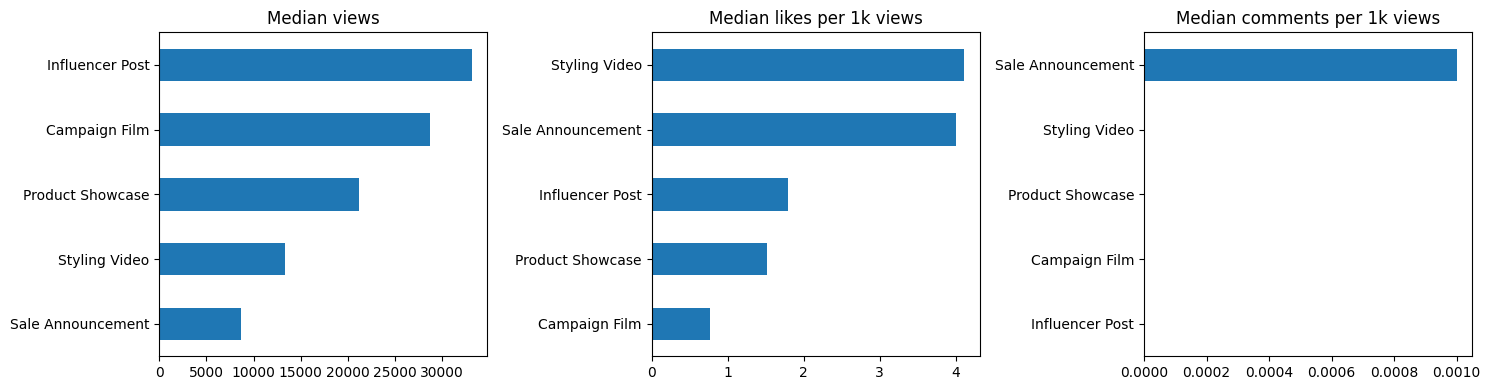

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MIN_VIEWS = 1000   # same threshold used for the anomaly step
MIN_GROUP = 15     # groups smaller than this are flagged as low-n

feat = pd.read_csv("data/clean/posts_features.csv")
seg = pd.read_csv("data/clean/comments_segments.csv")

# "Influencer Post (Short)" -> format_type + length_type
parts = feat["content_type"].astype(str).str.extract(r"^(.*?)\s*\((.*?)\)\s*$")
feat["format_type"] = parts[0].fillna(feat["content_type"])
feat["length_type"] = parts[1].fillna("Unknown")
feat["like_rate_per_1k"] = feat["likes"] / feat["views"] * 1000
feat["comment_rate_per_1k"] = feat["comments_count"] / feat["views"] * 1000

big = feat[feat["views"] >= MIN_VIEWS].copy()


def summarize(df, by):
    out = df.groupby(by).agg(
        videos=("post_id", "count"),
        median_views=("views", "median"),
        median_likes_per_1k=("like_rate_per_1k", "median"),
        median_comments_per_1k=("comment_rate_per_1k", "median"),
        zero_like_share=("likes", lambda s: (s == 0).mean()),
        total_views=("views", "sum"),
        total_likes=("likes", "sum"),
        total_comments=("comments_count", "sum"),
    )
    out["pooled_engagement_per_1k"] = (out["total_likes"] + out["total_comments"]) / out["total_views"] * 1000
    out["low_n"] = out["videos"] < MIN_GROUP
    return out.round(3).sort_values("median_views", ascending=False)


by_format = summarize(big, "format_type")
by_length = summarize(big, "length_type")
by_brand_format = summarize(big, ["brand", "format_type"])

print(f"Videos used (>= {MIN_VIEWS} views): {len(big)} of {len(feat)}\n")
show = ["videos", "median_views", "median_likes_per_1k", "median_comments_per_1k", "zero_like_share", "pooled_engagement_per_1k", "low_n"]
print("=== By content format ===");  print(by_format[show].to_string(), "\n")
print("=== By length (Short vs Long) ===");  print(by_length[show].to_string(), "\n")
print("=== Median likes per 1k views: brand x format ===")
print(by_brand_format["median_likes_per_1k"].unstack("brand").round(1).to_string(), "\n")

# what do people write under each format? (share of comments, %)
commercial_topics = ["price", "discount", "availability", "delivery", "size", "fabric_quality", "buying_intent", "customer_service"]
complaint_topics = ["negative_feedback", "customer_service", "delivery"]


def bucket(t):
    if t in commercial_topics:
        return "commercial"
    if t == "celebrity_music":
        return "celebrity_music"
    if t == "praise":
        return "praise"
    if t == "negative_feedback":
        return "negative_feedback"
    return "other_or_reaction"


seg2 = seg.merge(feat[["post_id", "format_type"]].drop_duplicates("post_id"), on="post_id", how="left")
seg2["bucket"] = seg2["topic"].map(bucket)
mix = (pd.crosstab(seg2["format_type"], seg2["bucket"], normalize="index") * 100).round(1)
mix["comments_n"] = seg2["format_type"].value_counts()
print("=== Comment mix by format (% of collected comments) ===")
print(mix.sort_values("commercial", ascending=False).to_string())

by_format.to_csv("data/clean/content_performance_by_format.csv", encoding="utf-8-sig")
by_length.to_csv("data/clean/content_performance_by_length.csv", encoding="utf-8-sig")
by_brand_format.to_csv("data/clean/content_performance_by_brand_format.csv", encoding="utf-8-sig")
mix.to_csv("data/clean/comment_mix_by_format.csv", encoding="utf-8-sig")

ok = by_format[~by_format["low_n"]]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ok["median_views"].sort_values().plot.barh(ax=ax[0], title="Median views")
ok["median_likes_per_1k"].sort_values().plot.barh(ax=ax[1], title="Median likes per 1k views")
ok["median_comments_per_1k"].sort_values().plot.barh(ax=ax[2], title="Median comments per 1k views")
for a in ax:
    a.set_ylabel("")
plt.tight_layout()
plt.show()

In [23]:
big["has_comment"] = big["comments_count"] > 0

extra = big.groupby("format_type").agg(
    videos=("post_id", "count"),
    videos_with_comments_pct=("has_comment", lambda s: s.mean() * 100),
    total_comments=("comments_count", "sum"),
    total_views=("views", "sum"),
)
extra["pooled_comments_per_1k_views"] = extra["total_comments"] / extra["total_views"] * 1000
extra = extra.round(3)
print("=== Comments by format (better metric) ===")
print(extra[["videos", "videos_with_comments_pct", "pooled_comments_per_1k_views"]].to_string(), "\n")

# save the better columns into the format file (used later by the app)
by_format = by_format.join(extra[["videos_with_comments_pct", "pooled_comments_per_1k_views"]])
by_format.to_csv("data/clean/content_performance_by_format.csv", encoding="utf-8-sig")

# how many videos sit behind each brand x format cell? (small cells = unreliable)
print("=== Videos per brand x format ===")
print(big.groupby(["brand", "format_type"]).size().unstack("brand").fillna(0).astype(int).to_string())

=== Comments by format (better metric) ===
                   videos  videos_with_comments_pct  pooled_comments_per_1k_views
format_type                                                                      
Campaign Film         318                    30.503                         0.033
Influencer Post       198                    41.919                         0.134
Product Showcase     1441                    34.004                         0.014
Sale Announcement      77                    50.649                         0.010
Styling Video          49                    38.776                         0.074 

=== Videos per brand x format ===
brand              Khaadi  Limelight  Sapphire
format_type                                   
Campaign Film          52        113       153
Influencer Post        25          2       171
Product Showcase      248         77      1116
Sale Announcement       8         58        11
Styling Video          21         15        13


In [24]:
import numpy as np
import pandas as pd

seg = pd.read_csv("data/clean/comments_segments.csv")
named = pd.read_csv("data/clean/comments_commercial_named.csv")
t = seg["text_clean"].fillna("")

neg_extra = (
    r"not received|still waiting|wrong|defect|missing|no response|no reply|not responding|scam|fraud|"
    r"worst|\bbad\b|\bbura\b|bakwas|bekar|disappoint|\bpoor\b|shame|overpriced|irresonable|unreasonable|"
    r"don'?t buy|dont buy|sucks|waste|\bfake\b|expensive|mehng|mahng|nahi acha|acha nahi|pathetic|horrible|terrible"
)
neg = (
    seg["has_negative_feedback"].astype(bool)
    | seg["has_customer_service"].astype(bool)
    | t.str.contains(neg_extra, case=False, regex=True)
)
pos = seg["has_praise"].astype(bool)

seg["sentiment"] = np.select(
    [neg & pos, neg, pos], ["Mixed", "Negative", "Positive"], default="Neutral"
)

print("Sentiment overall (%):")
print((seg["sentiment"].value_counts(normalize=True) * 100).round(1), "\n")
print("Sentiment by brand (% of each brand):")
print((pd.crosstab(seg["sentiment"], seg["brand"], normalize="columns") * 100).round(1), "\n")
print("Sentiment by segment (% of each segment):")
print((pd.crosstab(seg["segment"], seg["sentiment"], normalize="index") * 100).round(1), "\n")

final = seg.merge(named[["comment_id", "need_cluster", "need_name"]], on="comment_id", how="left")
final.to_csv("data/clean/comments_final.csv", index=False, encoding="utf-8-sig")
print("Saved data/clean/comments_final.csv:", len(final), "comments")

sample = seg.sample(100, random_state=7)[["comment_id", "comment_text", "sentiment"]].rename(
    columns={"sentiment": "rule_label"}
)
sample["my_label"] = ""
sample.to_csv("data/clean/sentiment_check_sample.csv", index=False, encoding="utf-8-sig")
print("\nWrote data/clean/sentiment_check_sample.csv")

Sentiment overall (%):
sentiment
Neutral     65.3
Positive    31.7
Negative     2.7
Mixed        0.3
Name: proportion, dtype: float64 

Sentiment by brand (% of each brand):
brand      Khaadi  Limelight  Sapphire
sentiment                             
Mixed         0.2        0.0       0.5
Negative      1.6        9.2       3.3
Neutral      61.2       69.4      69.5
Positive     37.0       21.5      26.8 

Sentiment by segment (% of each segment):
sentiment              Mixed  Negative  Neutral  Positive
segment                                                  
celebrity_local_chat     0.3       3.4     77.8      18.5
generic_praise           0.0       0.0     29.8      70.2
looks_and_beauty         0.4       0.8     28.2      70.6
music_seekers            0.0       0.3     71.9      27.8
shoppers_price_askers    1.0      10.2     62.3      26.5
short_reactions_hype     0.3       2.6     92.3       4.7 

Saved data/clean/comments_final.csv: 6228 comments

Wrote data/clean/sentiment_che

In [25]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.feature_extraction.text import TfidfVectorizer

final = pd.read_csv("data/clean/comments_final.csv")
com = final[final["need_name"].notna()].copy()

# ---- 1) one summary row per audience need ----
tf = TfidfVectorizer(min_df=2, max_df=0.5, stop_words="english", token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
X = tf.fit_transform(com["text_clean"].fillna(""))
vocab = np.array(tf.get_feature_names_out())

rows = []
for name, part in com.groupby("need_name"):
    idx = com.index.get_indexer(part.index)
    mean_vec = np.asarray(X[idx].mean(axis=0)).ravel()
    pool = part[part["word_count"] >= 3]
    ex = pool.sample(min(3, len(pool)), random_state=4)["comment_text"].astype(str).str.slice(0, 110).tolist()
    row = {
        "need_name": name,
        "comments": len(part),
        "share_of_shopping_comments_%": round(len(part) / len(com) * 100, 1),
        "strong_intent_%": round((part["purchase_intent"] == "Strong intent").mean() * 100, 1),
        "negative_%": round(part["sentiment"].isin(["Negative", "Mixed"]).mean() * 100, 1),
        "top_topics": ", ".join(f"{k} {v:.0%}" for k, v in part["topic"].value_counts(normalize=True).head(3).items()),
        "top_words": ", ".join(vocab[mean_vec.argsort()[::-1][:8]]),
        "examples": " | ".join(ex),
    }
    for b in sorted(final["brand"].dropna().unique()):
        row[f"n_{b}"] = int((part["brand"] == b).sum())
    rows.append(row)

needs = pd.DataFrame(rows).sort_values("comments", ascending=False)
needs.to_csv("data/clean/audience_needs_summary.csv", index=False, encoding="utf-8-sig")
print(needs.drop(columns=["examples"]).to_string(index=False))

# ---- 2) how trustworthy are the clusters? ----
commercial_cols = ["has_price", "has_discount", "has_availability", "has_delivery",
                   "has_size", "has_fabric_quality", "has_buying_intent", "has_customer_service"]
emb = np.load("data/clean/comment_embeddings.npy")
mask = final[commercial_cols].any(axis=1) | (final["segment"] == "shoppers_price_askers")
raw_com = pd.read_csv("data/clean/comments_commercial.csv")


def stability(E, k, seeds=10):
    labs = [KMeans(k, n_init=10, random_state=s).fit_predict(E) for s in range(seeds)]
    pair = [adjusted_rand_score(labs[i], labs[j]) for i in range(seeds) for j in range(i + 1, seeds)]
    return float(np.mean(pair)), labs[0]


print("\n=== Cluster stability: Adjusted Rand Index between 10 random restarts ===")
print("(1.0 = har baar same, ~0 = random; 0.5 se neeche ho to clusters ko 'soft themes' kahein)")
ari_all, _ = stability(emb, 6)
print(f"First-level segments (K=6, all {len(emb)} comments): mean ARI = {ari_all:.2f}")

sub_emb = emb[np.where(mask.values)[0]]
if len(sub_emb) == len(raw_com):
    ari_need, lab0 = stability(sub_emb, 7)
    vs_spark = adjusted_rand_score(lab0, raw_com["need_cluster"])
    print(f"Shopping-need clusters (K=7, {len(sub_emb)} comments): mean ARI = {ari_need:.2f}")
    print(f"Agreement of scikit-learn run with your Spark run: ARI = {vs_spark:.2f}")
else:
    ari_need = None
    print("Row count mismatch - skipped need-cluster stability")

for label, v in [("segments", ari_all), ("need groups", ari_need)]:
    if v is None:
        continue
    verdict = "stable" if v >= 0.7 else "moderately stable" if v >= 0.5 else "UNSTABLE - soft themes ki tarah likhein"
    print(f"Verdict for {label}: {verdict}")

                              need_name  comments  share_of_shopping_comments_%  strong_intent_%  negative_%                                        top_topics                                                        top_words  n_Khaadi  n_Limelight  n_Sapphire
               online_shopping_and_sale       225                          25.4             20.0        21.8 availability 19%, discount 16%, buying_intent 15%                hai, sale, plz, hain, online, chahiye, order, aur       100           29          96
                          brand_opinion       159                          18.0              8.2        10.1         fabric_quality 32%, other 23%, praise 19%         sapphire, khaadi, brand, good, love, best, khadi, colour        74            5          80
                           price_askers       144                          16.3              3.5        10.4      price 75%, discount 10%, customer_service 4%               price, sale, plz, expensive, need, buy, pink, suit

In [26]:
import pandas as pd

final = pd.read_csv("data/clean/comments_final.csv")
needs = pd.read_csv("data/clean/audience_needs_summary.csv")

# original names ko mehfooz rakhein taake cell dobara run ho sake
if "need_name_original" not in final.columns:
    final["need_name_original"] = final["need_name"]
if "need_name_original" not in needs.columns:
    needs["need_name_original"] = needs["need_name"]

# 1) har group ke 8 random examples dekhein
for name, part in final[final["need_name_original"].notna()].groupby("need_name_original"):
    print(f"\n=== {name} ({len(part)} comments) ===")
    pool = part[part["word_count"] >= 3]
    for s in pool.sample(min(8, len(pool)), random_state=11)["comment_text"].astype(str).str.slice(0, 120):
        print("  -", s)

# 2) naye naam (examples dekh kar yahan badal sakte hain)
renames = {
    "online_shopping_and_sale": "online_buyers_and_sale_hunters",
    "brand_opinion": "brand_opinion_and_fabric_praise",
    "price_askers": "price_askers",
    "contact_size_international_delivery": "contact_and_store_info_seekers",
    "delivery_charges_and_quality_complaints": "product_fabric_and_delivery_remarks",
    "collection_launch_and_how_to_order": "collection_praise_and_availability",
}
final["need_name"] = final["need_name_original"].map(renames).fillna(final["need_name_original"])
needs["need_name"] = needs["need_name_original"].map(renames).fillna(needs["need_name_original"])

final.to_csv("data/clean/comments_final.csv", index=False, encoding="utf-8-sig")
needs.to_csv("data/clean/audience_needs_summary.csv", index=False, encoding="utf-8-sig")
print("\nSaved. New names:")
print(needs[["need_name_original", "need_name", "comments"]].to_string(index=False))


=== brand_opinion (159 comments) ===
  - Because sapphire has got it all good comfort , perfect designs & reasonable price range 😍
  - Sapphire thnx for this shoot😂😂😂😂🎉🎉🎉🎉🎉
  - Khadi is one is the best brand
  - These designs are available in khaadi stores
  - Don't buy sapphire mara 9000 Ka loss hua
  - Khaadi collection are very good and excellent
  - Don't buy sapphire
  - Yes khadi which is a great brand I have worn it many times the khadi fabric is very soft and wearable in both winter and

=== collection_launch_and_how_to_order (89 comments) ===
  - Where is full recipe
  - Aao how to use shappier gift card
  - where can i buy
  - the stuff is very good i suggest to everyone is to buy
  - Level up designing 👍🏻❤️
  - Summer collection 2024 kb aye gi?
  - Want to buy it
  - So beautiful collection #healthandfashion

=== contact_size_international_delivery (140 comments) ===
  - Someone is doing fraud by fake winning scheme with the name of your company
  - V nice brand❤❤
  - Thank

In [27]:
import numpy as np
import pandas as pd

final = pd.read_csv("data/clean/comments_final.csv")
t = final["text_clean"].fillna("")

leak = (r"thank you for (?:choosing|showing your interest|contacting|reaching)"
        r"|we hope that you will|we.d love to hear|kindly visit|to order online|call 0800")
spam = r"promosm|crush your competition|sub my channel|subscribe to my"
final["is_brand_reply_or_spam"] = t.str.contains(leak + "|" + spam, case=False, regex=True)

renames = {
    "online_shopping_and_sale": "complaints_and_misc_shopping_issues",
    "brand_opinion": "brand_opinion_good_and_bad",
    "price_askers": "price_askers",
    "contact_size_international_delivery": "contact_requests_and_misc",
    "delivery_charges_and_quality_complaints": "availability_and_restock_requests",
    "collection_launch_and_how_to_order": "where_to_buy_and_collection_interest",
}
final["need_name"] = final["need_name_original"].map(renames)
final.loc[final["is_brand_reply_or_spam"], "need_name"] = np.nan   # rows stay, only leave the need groups

print("Flagged as brand reply / spam:", int(final["is_brand_reply_or_spam"].sum()))
print(final.loc[final["is_brand_reply_or_spam"], "brand"].value_counts().to_string(), "\n")
print("Examples of flagged comments:")
for s in final.loc[final["is_brand_reply_or_spam"], "comment_text"].astype(str).str.slice(0, 100).head(12):
    print("  -", s)

print("\nNeed groups now:")
print(final["need_name"].value_counts().to_string())

final.to_csv("data/clean/comments_final.csv", index=False, encoding="utf-8-sig")
print("\nSaved comments_final.csv")

Flagged as brand reply / spam: 8
brand
Limelight    5
Sapphire     2
Khaadi       1 

Examples of flagged comments:
  - To order online kindly visit pk.khaadi.com or call 0800 74007 to place your order.
  - Thank you for your valuable feedback, we'd love to hear same from you in future!
  - Thank you for showing your interest in our brand, we'd love to hear same from you in future!
  - Thank you for your valuable feedback, we'd love to hear same from you in future!
  - Thank you for choosing limelight. We hope that you will shop more from us!
  - Thank you for your valuable feedback, we'd love to hear same from you in future!
  - Your video is very nice!!! Crush your competition with *promosm*.
  - I am subbing everyone whoes sub my channel..so write done in a coment

Need groups now:
need_name
complaints_and_misc_shopping_issues     225
brand_opinion_good_and_bad              159
price_askers                            144
contact_requests_and_misc               137
availability_and_r

In [28]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

final = pd.read_csv("data/clean/comments_final.csv")
com = final[final["need_name"].notna()].copy()

tf = TfidfVectorizer(min_df=2, max_df=0.5, stop_words="english", token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
X = tf.fit_transform(com["text_clean"].fillna(""))
vocab = np.array(tf.get_feature_names_out())

rows = []
for name, part in com.groupby("need_name"):
    idx = com.index.get_indexer(part.index)
    mean_vec = np.asarray(X[idx].mean(axis=0)).ravel()
    pool = part[part["word_count"] >= 3]
    ex = pool.sample(min(3, len(pool)), random_state=4)["comment_text"].astype(str).str.slice(0, 110).tolist()
    row = {
        "need_name": name,
        "comments": len(part),
        "share_of_shopping_comments_%": round(len(part) / len(com) * 100, 1),
        "strong_intent_%": round((part["purchase_intent"] == "Strong intent").mean() * 100, 1),
        "negative_%": round(part["sentiment"].isin(["Negative", "Mixed"]).mean() * 100, 1),
        "top_topics": ", ".join(f"{k} {v:.0%}" for k, v in part["topic"].value_counts(normalize=True).head(3).items()),
        "top_words": ", ".join(vocab[mean_vec.argsort()[::-1][:8]]),
        "examples": " | ".join(ex),
    }
    for b in sorted(final["brand"].dropna().unique()):
        row[f"n_{b}"] = int((part["brand"] == b).sum())
    rows.append(row)

needs = pd.DataFrame(rows).sort_values("comments", ascending=False)
needs.to_csv("data/clean/audience_needs_summary.csv", index=False, encoding="utf-8-sig")
print(needs.drop(columns=["examples"]).to_string(index=False))

                           need_name  comments  share_of_shopping_comments_%  strong_intent_%  negative_%                                        top_topics                                                        top_words  n_Khaadi  n_Limelight  n_Sapphire
 complaints_and_misc_shopping_issues       225                          25.5             20.0        21.8 availability 19%, discount 16%, buying_intent 15%                hai, sale, plz, hain, online, chahiye, order, aur       100           29          96
          brand_opinion_good_and_bad       159                          18.0              8.2        10.1         fabric_quality 32%, other 23%, praise 19%         sapphire, khaadi, brand, good, love, best, khadi, colour        74            5          80
                        price_askers       144                          16.3              3.5        10.4      price 75%, discount 10%, customer_service 4%               price, sale, plz, expensive, need, buy, pink, suit        42  

In [29]:
import numpy as np
import pandas as pd

p = pd.read_csv("data/clean/posts_features.csv")
p["video_url"] = "https://www.youtube.com/watch?v=" + p["post_id"].astype(str)
p["like_rate_per_1k"] = p["likes"] / p["views"].replace(0, np.nan) * 1000
p["group_median_like_rate"] = p.groupby("group")["like_rate_per_1k"].transform("median")

u = p[p["is_unusual"]].copy()


def classify(r):
    zv, ze, zc = r["z_log_views"], r["z_log_engagement"], r["z_log_comments_rate"]
    reason = str(r["reason"])
    if "many complaints" in reason:
        return "Complaint hotspot"
    if "many shopping questions" in reason:
        return "Shopping-question hotspot"
    if zv >= 2 and ze >= 2:
        return "Breakout post (high reach AND high engagement)"
    if zv >= 2 and ze <= -1.5:
        return "Reach without interaction (possible paid push or hidden likes)"
    if zv <= -1 and ze >= 2:
        return "Small but very engaged"
    if zc >= 3.5:
        return "Conversation driver (many comments for its reach)"
    if ze >= 3.5:
        return "Unusually high engagement"
    return "Other unusual combination"


def explain(r):
    lr = r["like_rate_per_1k"]
    base = r["group_median_like_rate"]
    return (
        f"{int(r['views']):,} views, {int(r['likes']):,} likes ({lr:.1f} per 1k) "
        f"vs {base:.1f} per 1k typical for {r['group']}; {int(r['comments_count'])} comments"
    )


u["anomaly_type"] = u.apply(classify, axis=1)
u["explanation"] = u.apply(explain, axis=1)
u = u.sort_values("max_abs_z", ascending=False)
u.to_csv("data/clean/unusual_posts_explained.csv", index=False, encoding="utf-8-sig")

print("Unusual posts:", len(u), "of", len(p), "\n")
print(pd.crosstab(u["anomaly_type"], u["brand"], margins=True).to_string(), "\n")

for typ, grp in u.groupby("anomaly_type"):
    print(f"--- {typ} ({len(grp)}) ---")
    for _, r in grp.head(3).iterrows():
        print(f"  {r['brand']:9s} {str(r['title'])[:48]:48s} | {r['explanation']}")

Unusual posts: 64 of 3831 

brand                                                           Khaadi  Limelight  Sapphire  All
anomaly_type                                                                                    
Other unusual combination                                           14         14        32   60
Reach without interaction (possible paid push or hidden likes)       0          0         2    2
Shopping-question hotspot                                            1          0         1    2
All                                                                 15         14        35   64 

--- Other unusual combination (60) ---
  Khaadi    All The Good Things | SALE                       | 862,610 views, 7 likes (0.0 per 1k) vs 8.8 per 1k typical for Sale Announcement (Short); 1 comments
  Khaadi    Khaadi Spring | Linen Collection                 | 1,731 views, 43 likes (24.8 per 1k) vs 5.4 per 1k typical for Campaign Film (Short); 6 comments
  Limelight New Year sale i

In [30]:
import numpy as np
import pandas as pd

p = pd.read_csv("data/clean/posts_features.csv")
p["video_url"] = "https://www.youtube.com/watch?v=" + p["post_id"].astype(str)
p["like_rate_per_1k"] = p["likes"] / p["views"].replace(0, np.nan) * 1000

# typical (median) values of each group, using videos with at least 1,000 views
big = p[p["views"] >= 1000]
gm_views = big.groupby("group")["views"].median()
gm_like = big.groupby("group")["like_rate_per_1k"].median().replace(0, np.nan)

u = p[p["is_unusual"]].copy()
u["views_ratio"] = u["views"] / u["group"].map(gm_views)
u["like_ratio"] = u["like_rate_per_1k"] / u["group"].map(gm_like)


def classify(r):
    reason = str(r["reason"])
    vr, lr = r["views_ratio"], r["like_ratio"]
    if "many complaints" in reason:
        return "Complaint hotspot"
    if "many shopping questions" in reason:
        return "Shopping-question hotspot"
    if vr >= 5 and lr <= 0.25:
        return "Reach without interaction"
    if vr >= 5 and lr >= 2:
        return "Breakout (high reach and high likes)"
    if vr <= 0.5 and lr >= 3:
        return "Small reach but very engaged"
    if vr <= 0.5 and lr <= 0.25:
        return "Low reach and low interaction"
    if lr >= 3:
        return "High likes for its format"
    return "Other unusual combination"


def explain(r):
    return (
        f"{int(r['views']):,} views ({r['views_ratio']:.1f}x typical), "
        f"{int(r['likes']):,} likes ({r['like_ratio']:.2f}x typical like rate), "
        f"{int(r['comments_count'])} comments, format: {r['group']}"
    )


u["anomaly_type"] = u.apply(classify, axis=1)
u["explanation"] = u.apply(explain, axis=1)
u = u.sort_values("max_abs_z", ascending=False)
u.to_csv("data/clean/unusual_posts_explained.csv", index=False, encoding="utf-8-sig")

print("Unusual posts:", len(u), "\n")
print(pd.crosstab(u["anomaly_type"], u["brand"], margins=True).to_string(), "\n")
print("Ratios (describe):")
print(u[["views_ratio", "like_ratio"]].describe().round(2).to_string(), "\n")

for typ, grp in u.groupby("anomaly_type"):
    print(f"--- {typ} ({len(grp)}) ---")
    for _, r in grp.head(4).iterrows():
        print(f"  {r['brand']:9s} {str(r['title'])[:45]:45s} | {r['explanation']}")

Unusual posts: 64 

brand                                 Khaadi  Limelight  Sapphire  All
anomaly_type                                                          
Breakout (high reach and high likes)       3          1         1    5
High likes for its format                  0          0         1    1
Other unusual combination                  0          1         1    2
Reach without interaction                  7         10        22   39
Shopping-question hotspot                  1          0         1    2
Small reach but very engaged               4          2         9   15
All                                       15         14        35   64 

Ratios (describe):
       views_ratio  like_ratio
count        64.00       64.00
mean         54.78       13.51
std          94.22       27.64
min           0.03        0.00
25%           0.21        0.00
50%          37.20        0.01
75%          65.82        8.09
max         675.71      113.74 

--- Breakout (high reach and high likes

In [31]:
import json
import numpy as np
import pandas as pd

final = pd.read_csv("data/clean/comments_final.csv")
if "is_brand_reply_or_spam" in final.columns:
    final = final[~final["is_brand_reply_or_spam"].astype(bool)].copy()
perf = pd.read_csv("data/clean/content_performance_by_format.csv", index_col=0)
mix = pd.read_csv("data/clean/comment_mix_by_format.csv", index_col=0)
unusual = pd.read_csv("data/clean/unusual_posts_explained.csv")
needs = pd.read_csv("data/clean/audience_needs_summary.csv").set_index("need_name")

commercial_cols = ["has_price", "has_discount", "has_availability", "has_delivery",
                   "has_size", "has_fabric_quality", "has_buying_intent", "has_customer_service"]
brands = sorted(final["brand"].dropna().unique())
bn = final["brand"].value_counts()
shop = final[commercial_cols].any(axis=1)
recs = []


def add(area, priority, action, evidence, test=""):
    recs.append({"area": area, "priority": priority, "recommendation": action,
                 "evidence": evidence, "how_to_test": test})


def need(name):
    return needs.loc[name] if name in needs.index else None


# --- CONTENT: price questions ---
n_price = int(final["has_price"].sum())
rate = {b: final.loc[final["brand"] == b, "has_price"].mean() * 100 for b in brands}
top_b = max(rate, key=rate.get)
add("Content", "High",
    "Put the price and a product link in the first line of every product video's description, and pin a comment with the price.",
    f"{n_price} comments ask about price ({n_price / shop.sum():.0%} of shopping comments). "
    f"Highest share: {top_b} at {rate[top_b]:.1f}% of its comments ({bn[top_b]} comments for this brand).",
    "Publish the next 10 similar videos with the price in the caption and 10 without; compare the share of price questions.")

# --- CONTENT: music requests ---
music = {b: (final.loc[final["brand"] == b, "segment"] == "music_seekers").mean() for b in brands}
mb = max(music, key=music.get)
if music[mb] >= 0.08:
    add("Content", "Medium",
        "For campaign films, name the song in the description, pin the full-song link, and add a shop link in the same pinned comment.",
        f"{music[mb]:.0%} of {mb}'s comments are music requests (lowest brand: {min(music.values()):.0%}). These viewers are engaged but are not shopping.",
        "Compare a film with song credit plus shop link against one without: count music and shopping questions.")

# --- CONTENT: formats ---
okp = perf[~perf["low_n"].astype(bool)]
if len(okp) >= 2:
    best = okp["median_likes_per_1k"].idxmax()
    top_reach = okp["median_views"].idxmax()
    add("Content", "Medium",
        f"Test more '{best}' content: it earns the most likes per view. Most videos of this format come from a few brands, so start with a small test.",
        f"'{best}': median {okp.loc[best, 'median_likes_per_1k']:.1f} likes per 1k views ({int(okp.loc[best, 'videos'])} videos). "
        f"Highest reach: '{top_reach}' ({okp.loc[top_reach, 'median_views']:,.0f} median views).",
        "Keep product and budget the same and change only the format.")

# --- CONTENT: influencer posts ---
if "commercial" in mix.columns:
    ave = (mix["commercial"] * mix["comments_n"]).sum() / mix["comments_n"].sum()
    infl = [i for i in mix.index if "Influencer" in str(i)]
    if infl and mix.loc[infl[0], "commercial"] < ave:
        add("Content", "High",
            "Influencer posts attract talk about the person, not the product. Show the product, its price and where to buy it in the first 10 seconds, and repeat it in a pinned comment.",
            f"Only {mix.loc[infl[0], 'commercial']:.1f}% of comments under influencer posts are shopping-related "
            f"(average across formats: {ave:.1f}%), while celebrity/music comments are {mix.loc[infl[0], 'celebrity_music']:.1f}%.",
            "Re-cut one influencer video with an on-screen product card and compare its shopping-comment share with the original.")

# --- PROMOTIONS ---
n_disc = int(final["has_discount"].sum())
n_strong = int((final["purchase_intent"] == "Strong intent").sum())
add("Promotions", "Medium",
    "State clearly when a sale starts and ends and which items it covers, in the description and a pinned comment. Answer 'discount?' questions with the sale link.",
    f"{n_disc} comments ask about discounts or sales; {n_strong} comments show clear buying intent (inbox, DM, WhatsApp, order).",
    "Track clicks on the pinned link or use of a promo code.")

# --- CUSTOMER SERVICE: based on need groups ---
for nm, action, test in [
    ("where_to_buy_and_collection_interest",
     "Pin a comment explaining how to order (website, outlets, WhatsApp) and announce launch dates for new collections in advance.",
     "Compare this group's share of comments before and after the pinned FAQ."),
    ("availability_and_restock_requests",
     "When an item sells out, give a restock date or a notify-me link.",
     "Count restock requests before and after adding the notify-me link."),
    ("complaints_and_misc_shopping_issues",
     "Assign a person or a reply template for return, exchange and 'fraud' comments.",
     "Measure time to first reply and the share of negative comments."),
]:
    r = need(nm)
    if r is not None:
        add("Customer service", "High" if r["negative_%"] >= 15 else "Medium", action,
            f"'{nm}': {int(r['comments'])} comments ({r['share_of_shopping_comments_%']}% of shopping comments), "
            f"strong intent {r['strong_intent_%']}%, negative {r['negative_%']}%. Top words: {r['top_words']}.", test)

comp = final["topic"].isin(["customer_service", "delivery", "negative_feedback"])
cb = {b: comp[final["brand"] == b].mean() * 100 for b in brands}
wb = max(cb, key=cb.get)
add("Customer service", "Medium",
    "Reply to delivery, refund and wrong-item comments within 24 hours.",
    f"{int(comp.sum())} comments are complaints ({comp.mean():.1%}). Highest share: {wb} at {cb[wb]:.1f}%, "
    f"but this brand has only {bn[wb]} comments, so the difference is not reliable.",
    "Measure complaint comments per 1,000 and the time to first reply.")

# --- fake giveaway / scam warnings (only if there are enough comments) ---
scam_pat = r"winning scheme|fake (?:gift|link|page|account|giveaway|winning)|giveaway|lucky draw|gifts? (?:mil|milay)"
scam = final["text_clean"].fillna("").str.contains(scam_pat, case=False, regex=True)
print("Fake giveaway / scam-type comments found:", int(scam.sum()))
for s in final.loc[scam, "comment_text"].astype(str).str.slice(0, 110).head(6):
    print("  -", s)
if scam.sum() >= 3:
    add("Customer service", "Medium",
        "Pin a warning about fake giveaways and links that use the brand's name, and list the official channels.",
        f"{int(scam.sum())} comments mention fake giveaways or scam-like activity.",
        "Count such comments after the warning is pinned.")

# --- CAMPAIGN TESTING ---
rwi = unusual[unusual["anomaly_type"].astype(str).str.startswith("Reach without")]
if len(rwi):
    n_sale = int(rwi["group"].astype(str).str.startswith("Sale").sum())
    add("Campaign testing", "High",
        "Review the videos with very high views but almost no likes or comments together with whoever runs paid promotion. Judge sale videos by link clicks and orders, not likes.",
        f"{len(rwi)} videos have views far above their format's typical level but almost no likes; {n_sale} are sale announcements. "
        f"The cause (paid reach, Shorts feed, hidden likes) cannot be confirmed from public data.",
        "Put a unique link on one such video and compare clicks with views.")

small = unusual[unusual["anomaly_type"].astype(str).str.startswith("Small reach")]
hot = unusual[unusual["anomaly_type"].astype(str).str.startswith("Shopping-question")]
if len(small) or len(hot):
    ex = hot["title"].astype(str).str.slice(0, 40).tolist()[:2]
    add("Campaign testing", "Medium",
        "Promote a little the small videos where shoppers are asking questions, to see whether the same interest exists in a larger audience.",
        f"{len(small)} videos are highly engaged despite low views, and {len(hot)} have many shopping questions ({'; '.join(ex)}). "
        f"Video age is not in our data, so these may simply be newer videos.",
        "Spend a small budget on one such video and compare engagement per 1k views.")

recs_df = pd.DataFrame(recs)
order = {"High": 0, "Medium": 1, "Low": 2}
recs_df = recs_df.sort_values(["area", "priority"], key=lambda s: s.map(order) if s.name == "priority" else s)
recs_df.to_csv("data/clean/recommendations.csv", index=False, encoding="utf-8-sig")
json.dump(recs, open("data/clean/recommendations.json", "w"), indent=2, ensure_ascii=False)

for area, grp in recs_df.groupby("area"):
    print(f"\n######## {area.upper()} ########")
    for _, r in grp.iterrows():
        print(f"[{r['priority']}] {r['recommendation']}")
        print(f"      Evidence: {r['evidence']}")
        print(f"      Test:     {r['how_to_test']}")

Fake giveaway / scam-type comments found: 3
  - Yeh jo khaadi management ny link send kia hua pagal bewqoof bna rhy logo ko k share kro tu gifts mily gy or lo
  - Someone is doing fraud by fake winning scheme with the name of your company
  - Ye fake page tu nhe hai

######## CAMPAIGN TESTING ########
[High] Review the videos with very high views but almost no likes or comments together with whoever runs paid promotion. Judge sale videos by link clicks and orders, not likes.
      Evidence: 39 videos have views far above their format's typical level but almost no likes; 11 are sale announcements. The cause (paid reach, Shorts feed, hidden likes) cannot be confirmed from public data.
      Test:     Put a unique link on one such video and compare clicks with views.
[Medium] Promote a little the small videos where shoppers are asking questions, to see whether the same interest exists in a larger audience.
      Evidence: 15 videos are highly engaged despite low views, and 2 have many sho

In [32]:
import json
import pandas as pd

r = pd.read_csv("data/clean/recommendations.csv")

old = "Most videos of this format come from a few brands, so start with a small test."
new = "Its median is almost the same as 'Sale Announcement' and it has only 49 videos, so start with a small test."
r["recommendation"] = r["recommendation"].str.replace(old, new, regex=False)

m = r["recommendation"].str.contains("fake giveaways", regex=False)
r.loc[m, "priority"] = "Low"
r.loc[m, "evidence"] = r.loc[m, "evidence"] + " Weak evidence: only 3 comments, and one of them is a question rather than a report."

r.to_csv("data/clean/recommendations.csv", index=False, encoding="utf-8-sig")
json.dump(r.to_dict("records"), open("data/clean/recommendations.json", "w"), indent=2, ensure_ascii=False)
print(r[["area", "priority", "recommendation"]].to_string(index=False, max_colwidth=90))

            area priority                                                                             recommendation
Campaign testing     High Review the videos with very high views but almost no likes or comments together with wh...
Campaign testing   Medium Promote a little the small videos where shoppers are asking questions, to see whether t...
         Content     High Put the price and a product link in the first line of every product video's description...
         Content     High Influencer posts attract talk about the person, not the product. Show the product, its ...
         Content   Medium For campaign films, name the song in the description, pin the full-song link, and add a...
         Content   Medium Test more 'Styling Video' content: it earns the most likes per view. Its median is almo...
Customer service     High             Assign a person or a reply template for return, exchange and 'fraud' comments.
Customer service   Medium Pin a comment explaining how to order 

In [33]:
%%writefile app.py
import os

import pandas as pd
import streamlit as st

CLEAN = "data/clean"
MIN_VIEWS = 1000

st.set_page_config(page_title="Campaign Intelligence Engine", layout="wide")


@st.cache_data
def load(name):
    path = os.path.join(CLEAN, name)
    return pd.read_csv(path) if os.path.exists(path) else None


posts = load("posts_features.csv")
comments = load("comments_final.csv")
unusual = load("unusual_posts_explained.csv")
needs = load("audience_needs_summary.csv")
recs = load("recommendations.csv")

if posts is None or comments is None:
    st.error("Run the notebook first: posts_features.csv and comments_final.csv are missing.")
    st.stop()

if "is_brand_reply_or_spam" in comments.columns:
    comments = comments[~comments["is_brand_reply_or_spam"].astype(bool)]

# ---------- sidebar filters ----------
st.sidebar.header("Filters")
all_brands = sorted(posts["brand"].dropna().unique())
brands = st.sidebar.multiselect("Brand", all_brands, default=all_brands)
min_views = st.sidebar.number_input("Minimum views per video", 0, 1_000_000, MIN_VIEWS, step=500)
st.sidebar.caption(
    "Data: public YouTube videos and comments of Khaadi, Sapphire and Limelight, collected with the "
    "YouTube Data API. Comments are a collected sample, not every comment."
)

p = posts[posts["brand"].isin(brands) & (posts["views"] >= min_views)].copy()
p["format_type"] = p["content_type"].astype(str).str.extract(r"^(.*?)\s*\(")[0].fillna(p["content_type"])
p["like_rate_per_1k"] = p["likes"] / p["views"] * 1000
c = comments[comments["brand"].isin(brands)].copy()

shop_cols = ["has_price", "has_discount", "has_availability", "has_delivery", "has_size", "has_buying_intent"]

st.title("Pakistan Social Audience & Campaign Intelligence Engine")
k1, k2, k3, k4 = st.columns(4)
k1.metric("Videos analysed", f"{len(p):,}")
k2.metric("Comments analysed", f"{len(c):,}")
k3.metric("Shopping-related comments", f"{int(c[shop_cols].any(axis=1).sum()):,}")
k4.metric("Unusual videos flagged", f"{0 if unusual is None else int(unusual['brand'].isin(brands).sum()):,}")

t1, t2, t3, t4, t5 = st.tabs([
    "1. What content attracts attention",
    "2. What the audience wants",
    "3. Unusual posts",
    "4. Audience needs",
    "5. What to do next",
])

# ---------- tab 1 ----------
with t1:
    st.subheader("Which content attracts attention?")
    if p.empty:
        st.info("No videos match the filters.")
    else:
        g = p.groupby("format_type").agg(
            videos=("post_id", "count"),
            median_views=("views", "median"),
            median_likes_per_1k=("like_rate_per_1k", "median"),
            total_comments=("comments_count", "sum"),
            total_views=("views", "sum"),
        )
        g["comments_per_1k_views"] = (g["total_comments"] / g["total_views"] * 1000).round(3)
        g = g.drop(columns=["total_comments", "total_views"]).round(1).sort_values("median_views", ascending=False)
        a, b = st.columns(2)
        a.markdown("**Median views per video**")
        a.bar_chart(g["median_views"])
        b.markdown("**Median likes per 1,000 views**")
        b.bar_chart(g["median_likes_per_1k"])
        st.dataframe(g, use_container_width=True)
        st.caption("Small groups are noisy: check the videos column. Sale announcements are mostly Limelight videos.")

        mix = c.merge(p[["post_id", "format_type"]].drop_duplicates("post_id"), on="post_id", how="inner")
        if len(mix):
            st.markdown("**What people write under each format (% of comments)**")
            top_topics = ["price", "discount", "availability", "celebrity_music", "praise", "short_reaction"]
            mix["topic_group"] = mix["topic"].where(mix["topic"].isin(top_topics), "other")
            st.dataframe((pd.crosstab(mix["format_type"], mix["topic_group"], normalize="index") * 100).round(1),
                         use_container_width=True)

# ---------- tab 2 ----------
with t2:
    st.subheader("What does the audience want?")
    a, b = st.columns(2)
    a.markdown("**Comment topics**")
    a.bar_chart(c["topic"].value_counts())
    b.markdown("**Sentiment**")
    b.bar_chart(c["sentiment"].value_counts())
    st.markdown("**Topic mix by brand (% of the brand's comments)**")
    st.dataframe((pd.crosstab(c["topic"], c["brand"], normalize="columns") * 100).round(1), use_container_width=True)
    st.caption("Limelight has few comments, so its percentages are less reliable.")

    st.markdown("**Comment explorer**")
    f1, f2, f3 = st.columns(3)
    pick_topic = f1.selectbox("Topic", ["(all)"] + sorted(c["topic"].dropna().unique()))
    pick_int = f2.selectbox("Purchase intent", ["(all)", "Strong intent", "Possible inquiry", "None"])
    query = f3.text_input("Contains text")
    view = c
    if pick_topic != "(all)":
        view = view[view["topic"] == pick_topic]
    if pick_int != "(all)":
        view = view[view["purchase_intent"] == pick_int]
    if query:
        view = view[view["comment_text"].astype(str).str.contains(query, case=False, regex=False)]
    st.caption(f"{len(view):,} comments match")
    st.dataframe(view[["brand", "topic", "sentiment", "purchase_intent", "language_type", "comment_text"]].head(300),
                 use_container_width=True)

# ---------- tab 3 ----------
with t3:
    st.subheader("Which marketing patterns are unusual?")
    if unusual is None:
        st.info("unusual_posts_explained.csv not found.")
    else:
        u = unusual[unusual["brand"].isin(brands)]
        types = sorted(u["anomaly_type"].dropna().unique())
        pick = st.multiselect("Pattern type", types, default=types)
        u = u[u["anomaly_type"].isin(pick)]
        st.caption("Unusual means different from comparable videos of the same format. It is a prompt to investigate, "
                   "not a verdict. The cause of very high views with almost no likes cannot be confirmed from public data.")
        st.dataframe(
            u[["brand", "title", "content_type", "views", "likes", "comments_count", "anomaly_type", "explanation", "video_url"]],
            use_container_width=True,
            column_config={"video_url": st.column_config.LinkColumn("Video")},
        )

# ---------- tab 4 ----------
with t4:
    st.subheader("Which audience needs should the brand address?")
    st.markdown("**All comments: audience segments by brand (% of the brand's comments)**")
    st.dataframe((pd.crosstab(c["segment"], c["brand"], normalize="columns") * 100).round(1), use_container_width=True)
    st.markdown("**Shopping comments only: need groups**")
    if needs is None:
        st.info("audience_needs_summary.csv not found.")
    else:
        st.dataframe(needs.drop(columns=["examples"]), use_container_width=True)
        pick = st.selectbox("See example comments for", needs["need_name"])
        for ex in str(needs.loc[needs["need_name"] == pick, "examples"].iloc[0]).split(" | "):
            st.write("- " + ex)
    st.caption("Groups come from multilingual sentence embeddings and K-Means. They are soft themes: short comments overlap a lot.")

# ---------- tab 5 ----------
with t5:
    st.subheader("What should the marketing team do next?")
    if recs is None:
        st.info("recommendations.csv not found.")
    else:
        area = st.selectbox("Area", ["(all)"] + sorted(recs["area"].unique()))
        r = recs if area == "(all)" else recs[recs["area"] == area]
        for _, row in r.iterrows():
            with st.expander(f"[{row['priority']}] {row['area']}: {row['recommendation']}"):
                st.write("**Evidence:** " + str(row["evidence"]))
                if str(row.get("how_to_test", "")) not in ("", "nan"):
                    st.write("**How to test:** " + str(row["how_to_test"]))

Writing app.py


In [34]:
!pip install -q streamlit
!nohup streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1 &
!sleep 5
print("Tunnel password (paste it into the localtunnel page):")
!curl -s ipv4.icanhazip.com
!npx -y localtunnel --port 8501

Tunnel password (paste it into the localtunnel page):
34.173.146.136
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏your url is: https://petite-hats-listen.loca.lt
^C


In [35]:
!pkill -f "streamlit run"
!pkill -f cloudflared
!sleep 2
!nohup streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > streamlit.log 2>&1 &
!sleep 6
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!nohup ./cloudflared tunnel --url http://localhost:8501 > cf.log 2>&1 &
!sleep 12
!grep -o "https://[a-z0-9-]*\.trycloudflare\.com" cf.log | head -1

https://gossip-compatibility-laser-suited.trycloudflare.com
